# 06 — Modelling Setup (Part 2, Phase 4)

Establish the shared experiment contract before fitting predictive models: eligible inputs, frozen chronological partitions, expanding-month cross-validation, computational budgets, and uninformative baselines. Reusable logic lives in `Python/model_selection.py` and `Python/modelling_setup.py`.

**Prediction tasks:** pre-pricing interest-rate regression (`int_rate`, percentage points) and origination-time repayment classification (`0 Good`, `1 At risk`, `2 Default`). Rejected applications have no repayment targets and do not enter these supervised cohorts.

**Test policy:** no held-out outcomes or predictors are loaded here. Test counts below come from Part 1 metadata only; final test scoring belongs in Notebook 12.

In [1]:
import sys, json, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from Python.modelling_setup import ExperimentConfig, ModellingDataSetup, BaselineRunner
from Python.model_selection import MonthlyTimeSeriesCV
from Python.preprocessing import LendingClubPreprocessor

OUT = PROJECT_ROOT / 'outputs' / 'modelling_setup'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
config = ExperimentConfig()
setup = ModellingDataSetup(PROJECT_ROOT)
runner = BaselineRunner(config)
display(pd.Series(config.to_dict(), name='setting').to_frame())

,setting
seed,42
n_splits,5
classification_cv_min_train_end,2014-02
search_candidates,12
expensive_training_cap,50000
preprocessing_check_train,5000
preprocessing_check_validation,1000
regression_selection_metric,rmse
classification_selection_metric,f1_macro
neural_network_seeds,"(42, 43, 44)"


## 1. Freeze the protocol and budget

Reuse train ≤ 2014-12, validation 2015-01 through 2016-12, and held-out test ≥ 2017-01. Tune within training using five expanding calendar-month folds. Use validation for candidate comparisons and final decisions; freeze choices and the refit protocol before test evaluation.

RMSE is the primary regression selection metric; macro F1 is the primary classification metric. Report all required metrics. Initial search budget: at most 12 configurations per model (60 fold fits); expensive models may use up to 50,000 reproducibly sampled training rows per fold. Ordinary models should use the full training cohort when feasible. Record actual sizes, elapsed times, and any revised budgets in later notebooks. Evaluation rows stay identical across models within each task. No row sampling or rebalancing of the final test cohort.

For neural networks, reserve a chronological tail **inside each training fold** for early stopping; keep outer fold validation independent. Use three seeds, a maximum of 100 epochs, and patience 10. Sampling or class balancing must occur inside training folds only. These are budget settings, not runtime promises.

In [2]:
protocol = {
    'configuration': config.to_dict(), 'split': setup.split_config,
    'classification_labels': {'0': 'Good', '1': 'At risk', '2': 'Default'},
    'test_policy': 'Reserved for Notebook 12; outcomes not read in Notebook 06',
    'preprocessing': 'Fit every learned transform on the current training fold only',
    'sampling': 'Seeded training-only sampling; record indices and actual sizes',
    'final_refit': 'Freeze choices, refit on train + validation, then score test once',
    'interpretation': 'Retrospective chronological evaluation; not a historical backtest',
}
(OUT / 'experiment_config.json').write_text(json.dumps(protocol, indent=2))
assert setup.split_config['train_end'] == '2014-12'
assert setup.split_config['val_end'] == '2016-12'
display(pd.Series(setup.split_config, name='frozen_split'))

date_col     issue_d
train_end    2014-12
val_end      2016-12
Name: frozen_split, dtype: str

## 2. Audit cohorts, inputs, and chronological folds

Predictors come only from `predictor_plan.json`; source parquet files retain excluded fields and must never be passed wholesale to an estimator. The loader validates exclusions and target types, reads the development interval only, and sorts chronologically. Any learned feature selection or dimensionality reduction must also be refitted per training fold. Part 1 feature diagnostics are exploratory screening, not permission to select features using validation or test labels.

For regression, CV splits unique months into six consecutive blocks: the first is initial training, each subsequent block is validation with all earlier blocks as training. Blocks contain approximately equal numbers of months, **not loans**. A development-only class-count audit found that At risk first appears in December 2013. Uniform full-history folds would have no At risk training examples in any fold. Classification therefore uses initial training through February 2014 (33 At risk examples), followed by five two-month validation blocks in March–December 2014. These folds retain all three classes; minority counts remain sparse. This adjustment uses training data only and leaves the frozen external partitions unchanged. It also limits classification CV to a short, recent interval; report that limitation alongside variability.

In [3]:
saved_counts = json.loads((PROJECT_ROOT / 'outputs/split_ids.json').read_text())
cohorts, fold_rows, feature_rows, distributions = [], [], [], []
baseline_frames, confusion = [], {}
preprocessing_checks = []
for task in ['regression', 'classification']:
    train, validation = setup.load_development(task)
    target = 'int_rate' if task == 'regression' else 'target_class'
    predictors = setup.predictors(task)
    for kind in ['numeric', 'categorical']:
        for name in setup.predictor_plan[task][kind]:
            feature_rows.append(dict(task=task, feature=name, kind=kind))
    for partition, data in [('train', train), ('validation', validation)]:
        expected = saved_counts[task]['n_train' if partition == 'train' else 'n_val']
        assert len(data) == expected, f'{task} {partition} differs from Part 1'
        cohorts.append(dict(task=task, partition=partition, n=len(data),
                            date_min=data.issue_d.min(), date_max=data.issue_d.max(),
                            n_predictors=len(predictors), count_source='loaded development data'))
        if task == 'classification':
            for label in [0, 1, 2]:
                count = int((data[target] == label).sum())
                distributions.append(dict(task=task, partition=partition, label=label,
                                          count=count, proportion=count / len(data)))
        else:
            distributions.append(dict(task=task, partition=partition, label='int_rate',
                                      mean=data[target].mean(), std=data[target].std(),
                                      median=data[target].median()))
    cohorts.append(dict(task=task, partition='test_reserved', n=saved_counts[task]['n_test'],
                        count_source='Part 1 metadata only'))
    for fold, (a, b) in enumerate(MonthlyTimeSeriesCV(config.n_splits, min_train_end=config.classification_cv_min_train_end if task == 'classification' else None).split(train, groups=train.issue_d), 1):
        left, right = train.iloc[a], train.iloc[b]
        assert left.issue_d.max() < right.issue_d.min()
        assert not set(left.issue_d.dt.to_period('M')) & set(right.issue_d.dt.to_period('M'))
        row = dict(task=task, fold=fold, n_train=len(a), n_validation=len(b),
                   train_start=left.issue_d.min(), train_end=left.issue_d.max(),
                   validation_start=right.issue_d.min(), validation_end=right.issue_d.max())
        if task == 'classification':
            for label in [0, 1, 2]:
                row[f'train_class_{label}'] = int((left[target] == label).sum())
                row[f'validation_class_{label}'] = int((right[target] == label).sum())
                assert row[f'train_class_{label}'] > 0 and row[f'validation_class_{label}'] > 0
        fold_rows.append(row)
    results, matrices = runner.run(task, train, validation)
    baseline_frames.append(results)
    confusion.update(matrices)

    # Smoke-check the actual preprocessing pipeline on bounded samples.
    # These fitted objects are discarded; later experiments fit fresh pipelines per fold.
    fit_sample = train.sample(n=min(config.preprocessing_check_train, len(train)), random_state=config.seed)
    score_sample = validation.sample(n=min(config.preprocessing_check_validation, len(validation)), random_state=config.seed)
    plan = setup.predictor_plan[task]
    pre = LendingClubPreprocessor(plan['numeric'], plan['categorical'], task=task)
    fit_matrix = pre.fit_transform(fit_sample[predictors])
    score_matrix = pre.transform(score_sample[predictors])
    assert fit_matrix.shape[1] == score_matrix.shape[1]
    assert np.isfinite(fit_matrix).all() and np.isfinite(score_matrix).all()
    preprocessing_checks.append(dict(task=task, n_fit=len(fit_sample), n_transform=len(score_sample),
                                     n_encoded_features=fit_matrix.shape[1], finite=True))
    del train, validation, fit_sample, score_sample, pre, fit_matrix, score_matrix
    gc.collect()

cohort_table = pd.DataFrame(cohorts)
fold_table = pd.DataFrame(fold_rows)
feature_table = pd.DataFrame(feature_rows)
distribution_table = pd.DataFrame(distributions)
baselines = pd.concat(baseline_frames, ignore_index=True)
for name, table in [('cohorts', cohort_table), ('cv_folds', fold_table),
                    ('predictor_manifest', feature_table), ('target_distributions', distribution_table),
                    ('baseline_scores', baselines), ('preprocessing_checks', pd.DataFrame(preprocessing_checks))]:
    table.to_csv(OUT / f'{name}.csv', index=False)
display(cohort_table)
display(fold_table)
display(distribution_table)
display(pd.DataFrame(preprocessing_checks))

,task,partition,n,date_min,date_max,n_predictors,count_source
0,regression,train,466345,2007-06-01,2014-12-01,38.0,loaded development data
1,regression,validation,855502,2015-01-01,2016-12-01,38.0,loaded development data
2,regression,test_reserved,938821,NaT,NaT,NaN,Part 1 metadata only
3,classification,train,451671,2007-06-01,2014-12-01,44.0,loaded development data
4,classification,validation,678142,2015-01-01,2016-12-01,44.0,loaded development data
5,classification,test_reserved,249789,NaT,NaT,NaN,Part 1 metadata only


,task,fold,n_train,n_validation,train_start,train_end,validation_start,validation_end,train_class_0,validation_class_0,train_class_1,validation_class_1,train_class_2,validation_class_2
0,regression,1,2412,5865,2007-06-01,2008-09-01,2008-10-01,2009-12-01,NaN,NaN,NaN,NaN,NaN,NaN
1,regression,2,8277,16663,2007-06-01,2009-12-01,2010-01-01,2011-03-01,NaN,NaN,NaN,NaN,NaN,NaN
2,regression,3,24940,36118,2007-06-01,2011-03-01,2011-04-01,2012-06-01,NaN,NaN,NaN,NaN,NaN,NaN
3,regression,4,61058,125789,2007-06-01,2012-06-01,2012-07-01,2013-09-01,NaN,NaN,NaN,NaN,NaN,NaN
4,regression,5,186847,279498,2007-06-01,2013-09-01,2013-10-01,2014-12-01,NaN,NaN,NaN,NaN,NaN,NaN
5,classification,1,258809,34449,2007-06-01,2014-02-01,2014-03-01,2014-04-01,218436.0,28297.0,33.0,83.0,40340.0,6069.0
6,classification,2,293258,34370,2007-06-01,2014-04-01,2014-05-01,2014-06-01,246733.0,27838.0,116.0,86.0,46409.0,6446.0
7,classification,3,327628,45416,2007-06-01,2014-06-01,2014-07-01,2014-08-01,274571.0,36767.0,202.0,138.0,52855.0,8511.0
8,classification,4,373044,46182,2007-06-01,2014-08-01,2014-09-01,2014-10-01,311338.0,37050.0,340.0,150.0,61366.0,8982.0
9,classification,5,419226,32445,2007-06-01,2014-10-01,2014-11-01,2014-12-01,348388.0,26172.0,490.0,121.0,70348.0,6152.0


,task,partition,label,mean,std,median,count,proportion
0,regression,train,int_rate,13.828463,4.357966,13.66,NaN,NaN
1,regression,validation,int_rate,12.823919,4.644903,12.29,NaN,NaN
2,classification,train,0,NaN,NaN,NaN,374560.0,0.829276
3,classification,train,1,NaN,NaN,NaN,611.0,0.001353
4,classification,train,2,NaN,NaN,NaN,76500.0,0.169371
5,classification,validation,0,NaN,NaN,NaN,524595.0,0.773577
6,classification,validation,1,NaN,NaN,NaN,9491.0,0.013996
7,classification,validation,2,NaN,NaN,NaN,144056.0,0.212427


,task,n_fit,n_transform,n_encoded_features,finite
0,regression,5000,1000,101,True
1,classification,5000,1000,108,True


## 3. Baselines and cross-validation variability

Regression baselines predict the training mean or median. Classification baselines always predict the majority class; `prior` additionally returns training class frequencies, whereas `most_frequent` returns one-hot probabilities. Their hard-label metrics are therefore identical, but probability metrics can differ.

Classification uses fixed class order `[0, 1, 2]`, zero precision/recall/F1 for undefined class denominators, and macro/micro one-versus-rest AUC computed from probabilities. AUC is marked missing when an evaluation fold lacks a class. Macro AUC for a constant-score baseline is 0.5; micro AUC can exceed 0.5 because it pools unequal class prevalences and must not be interpreted as borrower-level discrimination. For single-label multiclass classification, micro precision, recall, and F1 equal accuracy.

Dummy predictors ignore features, so baseline fits use a constant placeholder matrix. This does not bypass a learned transformation: no preprocessing is needed for a constant predictor. The separate preprocessing check above confirms the existing feature pipeline can fit and transform bounded development samples.

In [4]:
metric_names = ['mae', 'rmse', 'r2', 'accuracy', 'precision_macro', 'recall_macro',
                'f1_macro', 'precision_micro', 'recall_micro', 'f1_micro',
                'auc_macro_ovr', 'auc_micro_ovr']
cv_scores = baselines[baselines.partition.str.startswith('cv_')]
summary_rows = []
for (task, model), group in cv_scores.groupby(['task', 'model']):
    for metric in metric_names:
        if metric in group and group[metric].notna().any():
            summary_rows.append(dict(task=task, model=model, metric=metric,
                                     cv_mean=group[metric].mean(), cv_std=group[metric].std(ddof=1),
                                     n_valid_folds=int(group[metric].notna().sum())))
cv_summary = pd.DataFrame(summary_rows)
cv_summary.to_csv(OUT / 'baseline_cv_summary.csv', index=False)
validation_scores = baselines[baselines.partition == 'validation'].copy()
validation_scores.to_csv(OUT / 'baseline_validation.csv', index=False)
for task in ['regression', 'classification']:
    display(Markdown(f'### {task.title()}'))
    display(cv_summary[cv_summary.task == task])
    display(validation_scores[validation_scores.task == task].dropna(axis=1, how='all'))
assert cv_summary.n_valid_folds.eq(config.n_splits).all(), 'Inspect undefined fold metrics'


### Regression

,task,model,metric,cv_mean,cv_std,n_valid_folds
18,regression,dummy_mean,mae,3.193909,0.674320,5
19,regression,dummy_mean,rmse,3.960455,0.845671,5
20,regression,dummy_mean,r2,-0.054325,0.090591,5
21,regression,dummy_median,mae,3.218924,0.661974,5
22,regression,dummy_median,rmse,3.991122,0.848225,5
23,regression,dummy_median,r2,-0.072700,0.105152,5


,task,model,partition,n_train,n_evaluation,mae,rmse,r2
5,regression,dummy_mean,validation,466345,855502,3.837982,4.752284,-0.046772
11,regression,dummy_median,validation,466345,855502,3.791029,4.719547,-0.032400


### Classification

,task,model,metric,cv_mean,cv_std,n_valid_folds
0,classification,dummy_most_frequent,accuracy,0.809969,0.007100,5
1,classification,dummy_most_frequent,precision_macro,0.269990,0.002367,5
2,classification,dummy_most_frequent,recall_macro,0.333333,0.000000,5
3,classification,dummy_most_frequent,f1_macro,0.298332,0.001441,5
4,classification,dummy_most_frequent,precision_micro,0.809969,0.007100,5
5,classification,dummy_most_frequent,recall_micro,0.809969,0.007100,5
6,classification,dummy_most_frequent,f1_micro,0.809969,0.007100,5
7,classification,dummy_most_frequent,auc_macro_ovr,0.500000,0.000000,5
8,classification,dummy_most_frequent,auc_micro_ovr,0.857477,0.005325,5
9,classification,dummy_prior,accuracy,0.809969,0.007100,5


,task,model,partition,n_train,n_evaluation,accuracy,precision_macro,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro,auc_macro_ovr,auc_micro_ovr
17,classification,dummy_most_frequent,validation,451671,678142,0.773577,0.257859,0.333333,0.290778,0.773577,0.773577,0.773577,0.5,0.830183
23,classification,dummy_prior,validation,451671,678142,0.773577,0.257859,0.333333,0.290778,0.773577,0.773577,0.773577,0.5,0.879791


## 4. Visual diagnostics

These figures concern development data only. A raw confusion matrix shows the impact of prevalence; the row-normalized matrix makes minority-class failures visible. Baseline CV variability reflects both different training sizes and changing vintages, not independent repeated estimates of a single fixed population.

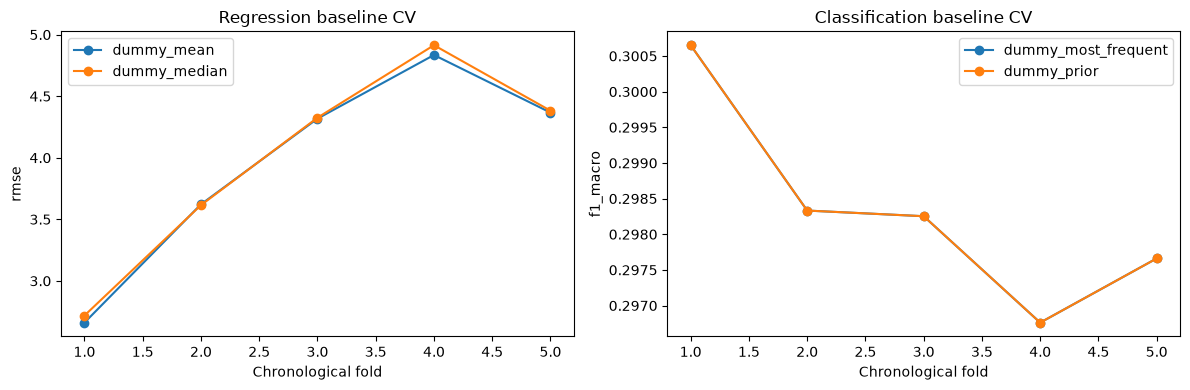

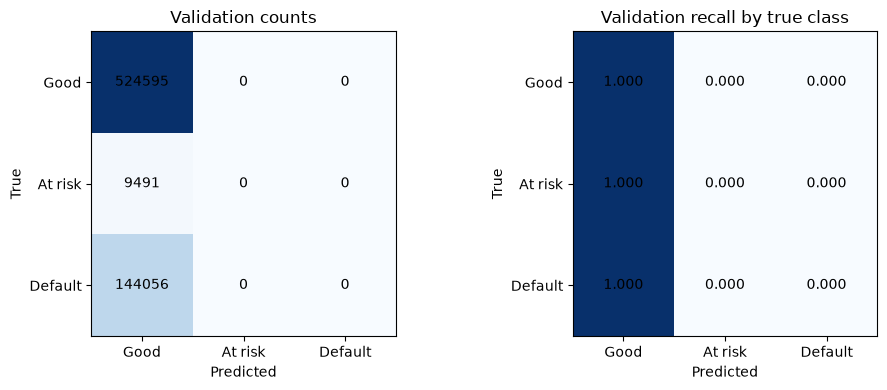

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, task, metric in zip(axes, ['regression', 'classification'], ['rmse', 'f1_macro']):
    for model, frame in cv_scores[cv_scores.task == task].groupby('model'):
        ax.plot(range(1, len(frame) + 1), frame[metric], marker='o', label=model)
    ax.set(title=f'{task.title()} baseline CV', xlabel='Chronological fold', ylabel=metric)
    ax.legend()
fig.tight_layout()
fig.savefig(FIG / 'baseline_cv.png', dpi=150)
plt.show()
labels = ['Good', 'At risk', 'Default']
matrix = confusion['prior']
pd.DataFrame(matrix, index=labels, columns=labels).to_csv(OUT / 'baseline_confusion_matrix.csv')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, values, title in zip(axes, [matrix, matrix / matrix.sum(axis=1, keepdims=True)],
                            ['Validation counts', 'Validation recall by true class']):
    ax.imshow(values, cmap='Blues')
    for (i, j), value in np.ndenumerate(values):
        ax.text(j, i, f'{value:.3f}' if values.dtype.kind == 'f' else str(value), ha='center', va='center')
    ax.set(xticks=range(3), yticks=range(3), xticklabels=labels, yticklabels=labels,
           xlabel='Predicted', ylabel='True', title=title)
fig.tight_layout()
fig.savefig(FIG / 'baseline_confusion_matrix.png', dpi=150)
plt.show()

## 5. Interpretation and handoff

Later notebooks must fit fresh preprocessing-plus-model pipelines per fold; never reuse the preprocessing demonstration or pre-transform the whole development cohort before CV. Derived-feature ablations and feature selection must use training-fold information. Maintain the same evaluation cohort even when training sizes differ.

The observed snapshot does not establish when repayment labels became available. Consequently these chronological folds are retrospective evaluations, not historical backtests. Selection of funded loans, exclusion of Current loans, unequal follow-up, potential repeated borrowers without reliable identifiers, and changing vintages limit generalization. Geography and other proxies require a separate group-performance assessment in final evaluation; aggregate baseline metrics do not establish fairness.

In [6]:
reg = validation_scores[validation_scores.task == 'regression'].set_index('model')
clf = validation_scores[validation_scores.task == 'classification'].set_index('model')
interpretation = f"""Development setup completed successfully.

- Cohort counts match Part 1, and all {len(fold_table)} task/fold combinations preserve month boundaries.
- Mean-predictor validation RMSE: {reg.loc['dummy_mean', 'rmse']:.3f} percentage points; MAE: {reg.loc['dummy_mean', 'mae']:.3f}.
- Median-predictor validation MAE: {reg.loc['dummy_median', 'mae']:.3f}; RMSE: {reg.loc['dummy_median', 'rmse']:.3f}.
- Majority-class validation accuracy: {clf.loc['dummy_prior', 'accuracy']:.2%}; macro F1: {clf.loc['dummy_prior', 'f1_macro']:.3f}. Minority-class recall is zero, so accuracy alone is inadequate.
- Prior baseline macro OVR AUC: {clf.loc['dummy_prior', 'auc_macro_ovr']:.3f}; micro OVR AUC: {clf.loc['dummy_prior', 'auc_micro_ovr']:.3f}. The latter reflects class prevalence rather than individual risk ranking.
- Classification CV uses March–December 2014 evaluation blocks because earlier At risk labels are absent or sparse; this is a substantial label-availability and follow-up limitation.
- Test outcomes remain unread. These are reference scores, not evidence that a useful predictive model has been built.
"""
display(Markdown(interpretation))
(OUT / 'analysis.md').write_text(interpretation)
print('Artifacts:', OUT.relative_to(PROJECT_ROOT))

Development setup completed successfully.

- Cohort counts match Part 1, and all 10 task/fold combinations preserve month boundaries.
- Mean-predictor validation RMSE: 4.752 percentage points; MAE: 3.838.
- Median-predictor validation MAE: 3.791; RMSE: 4.720.
- Majority-class validation accuracy: 77.36%; macro F1: 0.291. Minority-class recall is zero, so accuracy alone is inadequate.
- Prior baseline macro OVR AUC: 0.500; micro OVR AUC: 0.880. The latter reflects class prevalence rather than individual risk ranking.
- Classification CV uses March–December 2014 evaluation blocks because earlier At risk labels are absent or sparse; this is a substantial label-availability and follow-up limitation.
- Test outcomes remain unread. These are reference scores, not evidence that a useful predictive model has been built.


Artifacts: outputs/modelling_setup


## 6. What the observed results imply

The training mean interest rate is **13.828%**, versus **12.824%** in validation: a decline of about **1.005 percentage points**. The mean baseline consequently has negative validation R² (−0.0468); the median baseline is slightly better on this later cohort (RMSE 4.720 versus 4.752). Although the mean minimizes squared error on its fitting data, that guarantee does not extend to a shifted future distribution.

Classification also changes over time. Good loans fall from **82.93% to 77.36%**, Default increases from **16.94% to 21.24%**, and At risk rises from **0.135% to 1.400%**. The majority baseline achieves 77.36% accuracy while missing every At risk and Default loan. Its macro F1 is only **0.291**. The prior baseline's micro AUC of **0.880** despite constant borrower scores illustrates why macro AUC, per-class recall, and confusion matrices are essential.

Only **611** training observations belong to At risk. Before December 2013 there are none. The adjusted classification CV starts with **33** At risk training examples; its estimates will still be noisy and constrained to 2014 validation vintages. Later models should report per-fold class support and minority recall, compare training-only class weighting, and avoid claiming that these folds establish availability of historical outcomes. The observed pattern is consistent with snapshot/follow-up effects but does not prove their cause.

All development counts match Part 1. The preprocessing smoke checks produced **101 regression** and **108 classification** encoded columns on the bounded samples, with finite values and matching fit/transform widths. Full-fold category availability can change these widths; downstream estimators must use their own fitted pipelines.
